In [1]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.MNIST(root="~/.cache/", transform=transform, train=False)
print(train_data[0][0].shape)

torch.Size([1, 28, 28])


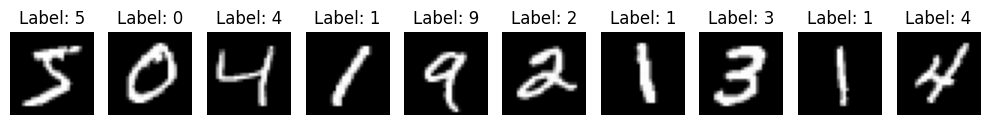

In [2]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from quantizer import VectorQuantizer


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),   # (28x28) → (14x14)
            nn.ReLU(),
            nn.Conv2d(16, 64, kernel_size=4, stride=2, padding=1),  # (14x14) → (7x7)
            nn.ReLU(),
            nn.Conv2d(64, 16, kernel_size=4, stride=2, padding=1),  # (7x7) → (4x4)
        )

    def forward(self, x):
        return self.encoder(x)  # (B, 16, 3, 3)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(16, 64, kernel_size=4, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
        )

    def forward(self, x):
        return self.decoder(x)  # (B, 1, 28, 28)


class VQVAE(nn.Module):
    def __init__(self, n_e, e_dim, norm_weight=True, beta=1.):
        super().__init__()
        self.encoder = Encoder()
        self.quantizer = VectorQuantizer(n_e, e_dim, norm_weight, beta)
        self.decoder = Decoder()

    def forward(self, x: torch.Tensor):
        # (B, C, H, W)
        z = self.encoder(x)
        z_q, indices, q_loss, codebook_usage = self.quantizer(z)
        x_q = self.decoder(z_q)

        return x_q, indices, q_loss, codebook_usage
    
    def encode(self, x: torch.Tensor):
        # (B, C, H, W)
        z = self.encoder(x)
        z_q, *_ = self.quantizer(z)
        return z_q
    
    def decode(self, z_q: torch.Tensor):
        # (B, C, H, W)
        x_q = self.decoder(z_q)
        return x_q

In [4]:
vqvae = VQVAE(n_e=128, e_dim=9)

x: torch.Tensor = train_data[0][0]
x = x.unsqueeze(0)  # 添加batch维度

x_q, indices, vq_loss, codebook_usage = vqvae(x) 
print(x_q.shape)
print(indices.shape) # use 16 tokens to encode one image
print(codebook_usage.shape)

z_q = vqvae.encode(x)
print(z_q.shape)



torch.Size([1, 1, 28, 28])
torch.Size([1, 16])
torch.Size([128])
torch.Size([1, 16, 3, 3])


In [5]:
vqvae = VQVAE(n_e=128, e_dim=9)

dataloader = torch.utils.data.DataLoader(train_data, batch_size=512, shuffle=True, num_workers=4)
optimizer = torch.optim.Adam(vqvae.parameters(), lr=1e-3)
epochs = 50

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


vqvae.to(device).train()
for epoch in range(epochs):
    for img, _ in dataloader:
        img = img.to(device)

        x_q, _, q_loss, _ = vqvae(img)
        loss = F.mse_loss(x_q, img) + q_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")



Epoch 1/50, Loss: 0.3422
Epoch 5/50, Loss: 0.1564
Epoch 10/50, Loss: 0.1373
Epoch 15/50, Loss: 0.1233
Epoch 20/50, Loss: 0.1157
Epoch 25/50, Loss: 0.1125
Epoch 30/50, Loss: 0.1101
Epoch 35/50, Loss: 0.1127
Epoch 40/50, Loss: 0.1100
Epoch 45/50, Loss: 0.1012
Epoch 50/50, Loss: 0.0987


[[126 112  86   5  81  78   8   0  55  18  26 121  17  55  28  60]
 [  0  98  81  37  82 100  31  40  50  22  57  40  23 102  68  61]
 [ 95 101  19  37  82   9   8 116 119  22  71  80 106  26  75  69]
 [ 85   6 112  90  66  32  79  11  45  10  15  94  23  45  24  17]
 [ 85 102  55  13   4  32  56  69  36  18 113  80 121  81  15  42]
 [ 95 101  86  81  82   9   8 116  67  22  71  80 106  34  75  69]
 [ 91 120  55  84  96 117  75 100 106  16  71  80  48  45  36  15]
 [ 85   6  89  92  82  98  64  53 119   3 113  80  48  27  19  90]
 [ 85 111  11  75  34  33  29  95 112  22 113  80  22  51 125  17]
 [  0 111  38  83  81  78  99  36  20   0  27  43  77  90  28  15]]


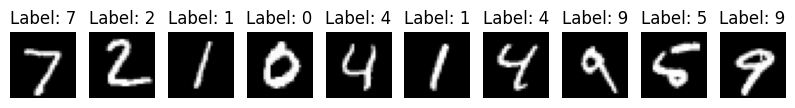

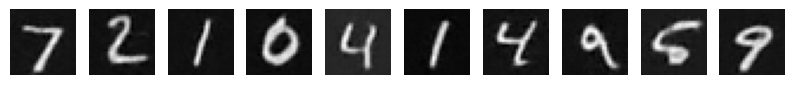

In [6]:
# 遍历前10张图片
x = torch.vstack([test_data[i][0] for i in range(10)]).unsqueeze(1).to(device)
x_q, ids, vq_loss, _ = vqvae(x)
x_q = x_q.cpu().detach()
x_p = vqvae.decode(vqvae.encode(x)).cpu().detach()

print(ids.cpu().numpy())

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = test_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = x_p[i], test_data[i][1]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.axis('off')  # 关闭坐标轴

2.1522947e-05


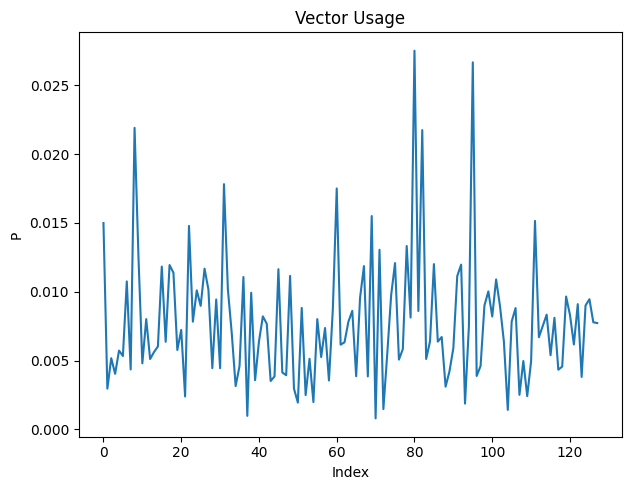

In [7]:
test_loader = torch.utils.data.DataLoader(test_data, batch_size=512, shuffle=False, num_workers=4)

vqvae.eval()
usage = 0
for img, _ in test_loader:
    img = img.to(device)

    _, _, _, u = vqvae(img)
    usage += u.cpu().numpy() * len(img)

usage /= len(test_data)

print(usage.var())
plt.figure(figsize=(12, 5))

# 折线图
plt.subplot(1, 2, 1)
plt.plot(usage)
plt.title('Vector Usage')
plt.xlabel('Index')
plt.ylabel('P')


plt.tight_layout()
plt.show()